# **Intro to SiS1 Labs**

The goal of the labs of Signal and Systems 1 is to gain knowledge on the course’s topics by solving a specific signal processing problem. By the end of the course, each group should be able to synthesize the sound produced by a plucked string instrument using the knowledge acquired in the theory and seminar classes. This will be a cumulative process, in each lab new techniques will be applied in order to improve the synthesis. First let's show what we will achieve by the end of the course. For each lab we need to import some auxiliary functions needed to load the audio files and listen to them:


In [2]:
from util import load_audio, save_audio, plot_signals
from IPython.display import Audio

**Reference signal**

Now let's load and listen to a reference signal like the one you will use:

In [3]:
reference, fs = load_audio('reference.wav')
Audio(reference, rate=fs)

**Synthesis**

Now we can load and listen to a synthesised signal like the one you will obtain and that tries to imitate the reference signal. This is an audio signal created from scratch only using the knowledge gained during the course.

In [4]:
synthesis, fs = load_audio('reference.wav')
Audio(synthesis, rate=fs)

---

## **Lab 1**
In this lab you will choose your reference sound to be used for all the labs and start imitating it with a single sinusoid.

## **Exercises**

**1. Choose a reference sound**

1.1. Find a recording of a single plucked string sound. Be creative, do not choose “guitar” by default, nor copy a sound from another group. You can use [Freesound](https://freesound.org/) to find the recordings (Freesound is a huge collaborative database of audio snippets released under Creative Commons licenses created and maintained by researchers of the Music Technology Group of the UPF). Try to find a sound with the best possible quality. The ideal sound format should be: uncompress (such as.wav, .aiff, but no .mp3), mono (one channel) and with a sampling rate of  44100Hz. The sound file should also contain a single note. You can start by downloading a sound from freesound and modify it with Audacity to the right format and content.

[Put here the freesound link to the selected sound recording]

1.2. Create a github repository and upload your edited audio file there:

1) Sing up to github using your UPF gmail account: https://github.com/

2) Create a repository called **sis1_groupX** where X is your group number: https://docs.github.com/en/get-started/quickstart/create-a-repo

3) Upload your edited audio file to the repository


1.3. Now you can clone your repository and access the audio file locally. Change the following code (user name and file name) to clone the repository and load the audio file.

In [5]:
filepath = "reference.wav"
ref, fs = load_audio(filepath)

Note that `load_audio` function returns two variables: the audio signal (as a one dimensional array of floating point numbers), and the sampling rate (as a integer number). Now we can plot the audio signal:

In [6]:
plot_signals(ref, fs)

You can use the zoom in tool to see more details.

You can also use Audio widget to listen the audio signal:

In [7]:
Audio(ref, rate=fs)



---



**2. Measure the signal period**

2.1. Find the note frequency (fundamental frequency) based on the musical note name given in the file name or description (i.e. A3 note corresponds to the frequency 220 Hz. See https://pages.mtu.edu/~suits/notefreqs.html).

[Write here the note and the fundamental frequency in hertz]

2.2. Calculate the period from the frequency value using Python:


In [8]:
frequency = 293.666  #Frequency of D4

period = 1 / frequency
print(f"The period of the signal is {period} seconds.")

The period of the signal is 0.003405229069759523 seconds.


2.3. Plot three periods of the signal using the `plot_signals` function and selecting `t_start` and `t_end` arguments accordingly. Try to get the first periods of the audio signal but avoiding the attack section.

In [9]:

t_start = 2 #we avoid attack section, approximately 2 seconds
t_end = t_start + 3 * period # taking 3 periods

# Plot the signal
plot_signals(reference, fs, t_start, t_end)

2.4. Measure the period of the signal manually by identifying the begining and ending of a periodic cycle. Note that when you hover the mouse over one of the points in the plot, you can see the time and amplitude values. For instance, you can check the cross by zero.

0,003356

2.5. Do the measured (2.4) and theoretical (2.2) periods coincide? If not, explain why.

We measured 0,003356 and the theoretical is 0.003405. The difference between periods is about 0,0049.



---



**3. Generating a sinusoid**

3.1. Create a sinusoid of the same duration than the reference signal and same frequency than the fundamental frequency. Plot it along with the audio signal of the reference recording. Plot the same time segment that 2.3. Note that the sampling rate should be the same for both signals. Try to find the values of Amplitude and initial Phase that make the two signal segments plotted to match as close as possible (do not attempt to imitate the whole signal). Matching the phase is a bit tricky.



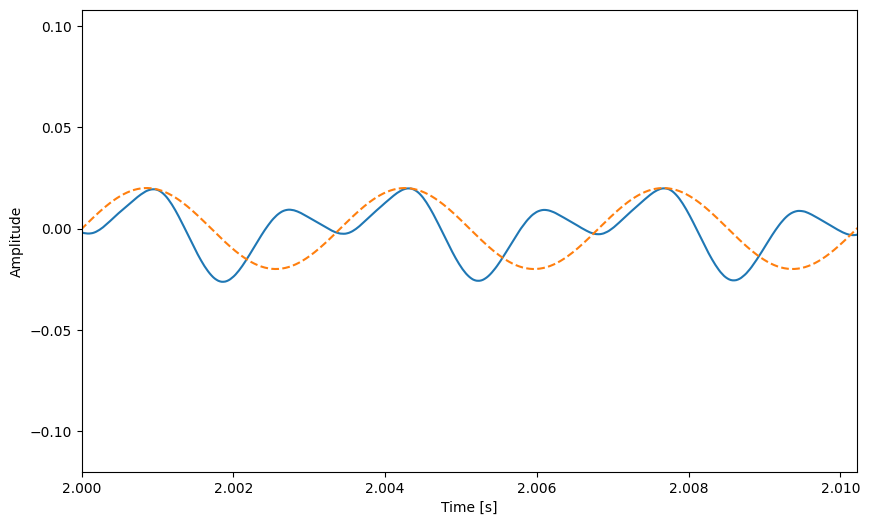

In [39]:
import numpy as np
import matplotlib.pyplot as plt #we used matplotlib to plot the signals, we prefered it over plotly

# Duration of the reference signal
duration = len(ref) / fs
# Time array
t = np.linspace(0, duration, len(ref)) #time array from 0 to duration with the same length as the signal

amplitude = 0.02  
phase = - 2*np.pi / 3  # We tried to approximate it the best we could, but it is not perfect
sinusoid = amplitude * np.sin(2 * np.pi * frequency * t + phase)

# Plot the reference signal and the sinusoid
plt.figure(figsize=(10, 6))
plt.plot(t, ref, label='Reference Signal')
plt.plot(t, sinusoid, label='Sinusoid', linestyle='--')
plt.xlim(t_start, t_end)
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.show()

3.2. What are the main differences between the two signals.


1. **Amplitude Variation**: Reference signal varies, synthesized is constant.
2. **Harmonics**: Reference has multiple harmonics, synthesized is a pure tone.
3. **Phase**: Reference phase varies, synthesized has fixed phase.
4. **Noise and Artifacts**: Reference may have noise, synthesized is clean.
5. **Attack and Decay**: Reference has attack/decay phases, synthesized does not.

In conclusion we can say that the reference signal does not have yet a sinusoidal form, nonetheless it is periodic.

3.3. Listen to the synthesized signal usign the Audio widget. Sounds natural?

In [ ]:
Audio(sinusoid, rate=fs)

Does not sound natural at all, it is a note created synthetically, and does not exist any sound as perfect.

3.4. Save the synthesized signal using the "save_audio" function:

In [40]:

save_audio('synthesized_signal.wav', sinusoid, fs)